<a href="https://colab.research.google.com/github/crisjodimo/Manual-de-R/blob/master/Google_colab_Rnotebook_temp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Title**

## ***Subtitele***

Claudiu Papasteri

<i>Native R Google Colab Template</i>

- Info: Template for self-contained data science projects
- Equivalent R Notebook: https://claudiupapasteri.github.io/notebooks/r-notebook-template/r-notebook-template.nb.html

[My Github notebooks](https://github.com/ClaudiuPapasteri/notebooks)

## Global Parameters


```
# Set Global Parameters here
```

In [1]:
options(rlang_interactive = TRUE)  # needed to mount Google Drive

In [2]:
cat("R version: ")
R.Version()$version.string

cat("Number of cores: ")
library(parallel)
parallel::detectCores(all.tests = FALSE, logical = TRUE)

R version: 

[1] "R version 4.6.1 (2026-06-24)"

Number of cores: 

[1] 2

---

## Install & load packages

In [3]:
load.libs <-
  c(
    "tidyverse", "ggplot2", "DT",
    "googledrive", "googlesheets4"
   )
install.libs <- load.libs[!load.libs %in% installed.packages()]
for(libs in install.libs) install.packages(libs, dependences = TRUE)
sapply(load.libs, require, character = TRUE)
rm(list = ls())

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘lazyeval’, ‘crosstalk’


Loading required package: tidyverse

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: DT

Loading required package: googledrive

Loading required package: googlesheets4


Attaching package: ‘googlesheets4’


The following objects are masked from ‘package:googledrive’:

    request_generate, request_make




tidyverse       ggplot2            DT   googledrive googlesheets4 
         TRUE          TRUE          TRUE          TRUE          TRUE

---

# Define functions


In [4]:
###############################################################################
# Define function
###############################################################################




---

# Mount Google Drive

In [5]:
# Mount Google Drive in an R kernel
library("googledrive")
library("googlesheets4")

# Check if is running in Colab and redefine is_interactive()
if (file.exists("/usr/local/lib/python3.7/dist-packages/google/colab/_ipython.py")) {
  suppressMessages({
    install.packages("R.utils")
    library(R.utils)
    library(httr)
    library(rlang)
  })
  my_check <- function() {return(TRUE)}
  reassignInPackage("is_interactive", pkgName = "httr", my_check)
  reassignInPackage("is_interactive", pkgName = "rlang", my_check)
}

# Call Google Drive authentication forcing interactive login and save in cache
googledrive::drive_auth(use_oob = TRUE, cache = TRUE)

Please point your browser to the following url: 

https://accounts.google.com/o/oauth2/v2/auth?client_id=603366585132-frjlouoa3s2ono25d2l9ukvhlsrlnr7k.apps.googleusercontent.com&scope=https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fdrive%20https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fuserinfo.email&redirect_uri=https%3A%2F%2Fwww.tidyverse.org%2Fgoogle-callback%2F&response_type=code&state=4d63c53b572b02366f68bb798e829b7c&access_type=offline&prompt=consent



Enter authorization code: eyJjb2RlIjoiNC8wQVVuNkhkOE4xOVpGSDVNMFhDNF9FTlBhTnVLSU5QaGZ4RE55WHFEZGo2WkY1eUFpVGhoVjhuT0poQ2ZnMkt6WG9SNld3dyIsInN0YXRlIjoiNGQ2M2M1M2I1NzJiMDIzNjZmNjhiYjc5OGU4MjliN2MifQ==


# Load data from Google Sheet in Google Drive

In [6]:
# Find Google Sheets
Sheets <- googledrive::drive_find(type = "spreadsheet")

# Reuse token to Sheet authentification
googlesheets4::gs4_auth(token = drive_token())

# Read first Google Sheet in Google Drive
sheet_data <- googlesheets4::range_read(Sheets$id[1])



✔ Reading from "2026- I Asistencia clase espejo DP (Respuestas)".

✔ Range Respuestas de formulario 1.



# Load data, processing, scoring

In [7]:
###############################################################################
# Load data
###############################################################################

# Load from package
rawdata <- ggplot2::diamonds

###############################################################################
# Processing data
###############################################################################
processed_data <-
  rawdata %>%
  dplyr::filter(carat <= 2.5)

# Run code from Github gist

In [8]:
devtools::source_gist("https://gist.github.com/C-C-P/32869ae032ead6ebb2167554108dad12")    # use also devtools::source_url()

ℹ Sourcing gist "32869ae032ead6ebb2167554108dad12"
ℹ SHA-1 hash of file is "4b315ce7e2f6bd3311f67d5b46d6330cc85fd84b"


[1] 42
Correct, the number is 42

## Output table - _knitr_



In [9]:
# tibble output
processed_data[1:3, ]

# ??? knitr kable
processed_data[1:3, ] %>%
  knitr::kable(caption = "A knitr kable.",
               format = "simple"
              )

carat,cut,color,clarity,depth,table,price,x,y,z
<dbl>,<ord>,<ord>,<ord>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
0.23,Ideal,E,SI2,61.5,55,326,3.95,3.98,2.43
0.21,Premium,E,SI1,59.8,61,326,3.89,3.84,2.31
0.23,Good,E,VS1,56.9,65,327,4.05,4.07,2.31




Table: A knitr kable.

 carat  cut       color   clarity    depth   table   price      x      y      z
------  --------  ------  --------  ------  ------  ------  -----  -----  -----
  0.23  Ideal     E       SI2         61.5      55     326   3.95   3.98   2.43
  0.21  Premium   E       SI1         59.8      61     326   3.89   3.84   2.31
  0.23  Good      E       VS1         56.9      65     327   4.05   4.07   2.31

## Output plot

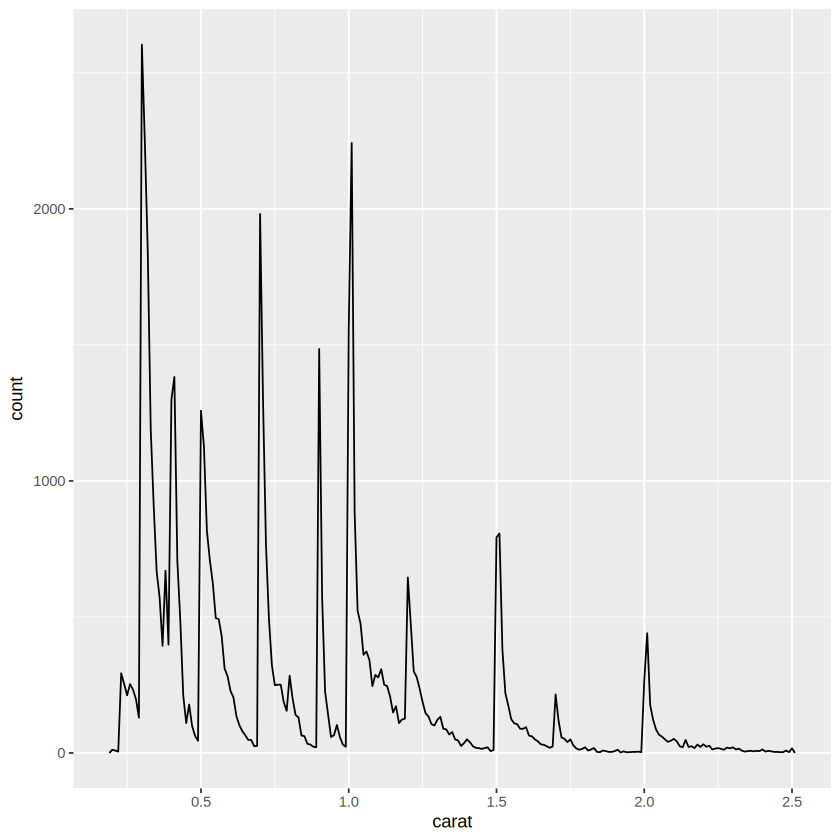

In [10]:
# Plot
processed_data %>%
  ggplot(aes(carat)) +
    geom_freqpoly(binwidth = 0.01)

# Save data to Google Sheet

In [11]:
# Reuse token to Sheet authentification
googlesheets4::gs4_auth(token = drive_token())

# Data for export
data_output <- head(iris)

# Name Sheet that will be created
gsheet_name <- paste ("Rnotebook Google colab Sheet", Sys.time(), sep = " ")

# Create Sheet in Google Drive
if(googlesheets4::gs4_has_token()) {
  gsheet_obj <- googlesheets4::gs4_create(
    name = gsheet_name,
    sheets = list(Sheet1 = data_output)    # Data goes in here
    )
}

# Check Sheet info
gsheet_obj

# Open a Sheet in default web browser
# googlesheets4::gs4_browse(gsheet_obj)   # works only in interactive, not in Google colab
# Print a Sheet URL
googlesheets4::gs4_get(googlesheets4::gs4_find(gsheet_name))$spreadsheet_url %>%
  httr::BROWSE()

✔ Creating new Sheet: Rnotebook Google colab Sheet 2026-11-17 18:55:36.964722.



── <googlesheets4_spreadsheet> ─────────────────────────────────────────────────
Spreadsheet name: Rnotebook Google colab Sheet 2026-11-17 18:55:36.964722
              ID: 1ZoPjPcs8iRoeTZ3ACfZxtSXHYEWwT-JnNB3XkhOOkCY           
          Locale: es_MX                                                  
       Time zone: Etc/GMT                                                
     # of sheets: 1                                                      

── <sheets> ────────────────────────────────────────────────────────────────────
(Sheet name): (Nominal extent in rows x columns)
      Sheet1: 7 x 5



Please point your browser to the following url: 

https://docs.google.com/spreadsheets/d/1ZoPjPcs8iRoeTZ3ACfZxtSXHYEWwT-JnNB3XkhOOkCY/edit



## Delete Sheet from Google Drive

In [12]:
# Delete Sheet form Google Drive
googledrive::drive_trash(gsheet_obj)          # good for removing in same session (obj still in memory)
# googlesheets4::gs4_find(gsheet_name) %>%   # good for removing in different session
#   googledrive::drive_trash()

File trashed:

• Rnotebook Google colab Sheet 2026-11-17 18:55:36.964722
  <id: 1ZoPjPcs8iRoeTZ3ACfZxtSXHYEWwT-JnNB3XkhOOkCY>



## Sesion Info


```
# Info formatted as code
```

In [13]:
Sys.info()

sysname                               release 
                              "Linux"                            "6.6.159+" 
                              version                              nodename 
"#1 SMP Thu Oct 22 03:07:54 UTC 2026"                        "9aa99cc6e968" 
                              machine                                 login 
                             "x86_64"                             "unknown" 
                                 user                        effective_user 
                               "root"                                "root"